In [25]:
from typing import List, Literal,TypedDict
from pydantic import BaseModel,Field
from pypdf import PdfReader
from langchain_community.vectorstores import FAISS
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate
from langchain_groq import ChatGroq
from langchain_google_genai  import ChatGoogleGenerativeAI, GoogleGenerativeAIEmbeddings 
from langchain_community.tools.tavily_search import TavilySearchResults
import re
from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv

In [2]:
load_dotenv()

True

In [3]:
#---------------LOAD DOCS-----------------------------------
#Helper function to replicate PyPDFLoader
def load_pdf_as_documents(file_path: str) -> list[Document]:
    try:
        reader = PdfReader(file_path)
        documents = []

        for i, page in enumerate(reader.pages):
            text = page.extract_text() or ""
            # Replicates LangChain's default metadata schema for loaders
            metadata = {"source": file_path, "page": i}
            documents.append(Document(page_content=text, metadata=metadata))

        return documents
    except Exception as e:
        print(f"Error loading {file_path}: {e}")
        return []


# Combining docs identically
docs = (
    load_pdf_as_documents("./documents/book1.pdf")
    #+ load_pdf_as_documents("./documents/book2.pdf")
    #+ load_pdf_as_documents("./documents/book3.pdf")   
)

In [4]:
len(docs)

758

In [5]:
#-----------------------------------CHUNKING--------------------------------
#chunking the documents using Recursive Character text splitter
chunks = RecursiveCharacterTextSplitter(chunk_size =900, chunk_overlap =100).split_documents(docs)

#---------------------------Clean text to avoid UnicodeEncodeError-------------------

for d in chunks:
    d.page_content = d.page_content.encode("utf-8", "ignore").decode("utf-8", "ignore")

In [6]:
len(chunks)

2421

In [13]:
#-----------------------Indexing------------------------------ 
#(fresh collection each run)
#------------------------------EMBED DOCS-----------------------------------
#Generating Embeddings for given docs using text-embedding-004 from google generative ai embeddings

embeddings = GoogleGenerativeAIEmbeddings(
    model = "gemini-embedding-001",# or 'models/gemini-embedding-exp-03-07'
    task_type="retrieval_document"# Options: retrieval_query, retrieval_document, semantic_similarity, etc.
)

In [14]:
import time

# Define safe batch settings for Gemini's Free Tier
# A batch size of 5 with a 4-second sleep guarantees staying under 100 RPM
BATCH_SIZE = 5
SLEEP_TIME_SECONDS = 4
vector_store = None

print(f"Starting vector database creation for {len(chunks)} text chunks...")

for i in range(0, len(chunks), BATCH_SIZE):
    batch = chunks[i : i + BATCH_SIZE]
    
    if vector_store is None:
        # Create the initial vector database using the first chunk batch
        vector_store = FAISS.from_documents(batch, embeddings)
    else:
        # Add subsequent chunks to the active store instance
        vector_store.add_documents(batch)
        
    current_chunk_count = min(i + BATCH_SIZE, len(chunks))
    print(f"Embedded [{current_chunk_count}/{len(chunks)}] chunks. Pausing briefly...")
    
    # Sleep prevents hitting the 429 Resource Exhausted threshold
    time.sleep(SLEEP_TIME_SECONDS)

print("\n Success! All text chunks embedded and vector store created.")


Starting vector database creation for 2421 text chunks...
Embedded [5/2421] chunks. Pausing briefly...
Embedded [10/2421] chunks. Pausing briefly...
Embedded [15/2421] chunks. Pausing briefly...
Embedded [20/2421] chunks. Pausing briefly...
Embedded [25/2421] chunks. Pausing briefly...
Embedded [30/2421] chunks. Pausing briefly...
Embedded [35/2421] chunks. Pausing briefly...
Embedded [40/2421] chunks. Pausing briefly...
Embedded [45/2421] chunks. Pausing briefly...
Embedded [50/2421] chunks. Pausing briefly...
Embedded [55/2421] chunks. Pausing briefly...
Embedded [60/2421] chunks. Pausing briefly...
Embedded [65/2421] chunks. Pausing briefly...
Embedded [70/2421] chunks. Pausing briefly...
Embedded [75/2421] chunks. Pausing briefly...
Embedded [80/2421] chunks. Pausing briefly...
Embedded [85/2421] chunks. Pausing briefly...
Embedded [90/2421] chunks. Pausing briefly...
Embedded [95/2421] chunks. Pausing briefly...
Embedded [100/2421] chunks. Pausing briefly...
Embedded [105/2421] ch

KeyboardInterrupt: 

In [15]:
#-------------------------RETRIEVER-----------------------------
#Creating a retriever using vector store
retriever =  vector_store.as_retriever(search_type='similarity',search_kwargs ={"k":4})

In [16]:
retriever

VectorStoreRetriever(tags=['FAISS', 'GoogleGenerativeAIEmbeddings'], vectorstore=<langchain_community.vectorstores.faiss.FAISS object at 0x0000024F9DFDA630>, search_kwargs={'k': 4})

In [17]:
#---------------------------LLM-------------------------------
llm = ChatGroq(model="llama-3.3-70b-versatile", temperature=0.2)
#llm = ChatGoogleGenerativeAI(model = "gemini-2.5-flash",temperature = 0)

In [36]:
#-------------------- Graph State ---------------------------------------
class State(TypedDict):
    question: str
    docs: List[Document]

    strips : List[str]# output of decomposition (sentence strips)
    kept_strips : List[str] # after filtering (kept sentences)
    refined_context : str # recomposed internal knowledge (joined kept_strips)
    
    answer: str

In [37]:
#------------------------------NODES DEFINITION---------------------------------------
def retrieve(state:State) -> State:
    query = state["question"]
    return {"docs": retriever.invoke(query)}

In [38]:
#----------------------------HELPER functions -------------------------------

# Sentence-level DECOMPOSER
def decompose_to_sentences(text:str) -> List[str]:
    text = re.sub(r"\s+", " ", text).strip()
    sentences = re.split(r"(?<=[.!?])\s+", text)
    return [s.strip() for s in sentences if len(s.strip()) > 20]


# FILTER (LLM as judge) 
from pydantic import BaseModel, Field, model_validator
from langchain_core.prompts import ChatPromptTemplate

class KeepOrDrop(BaseModel):
    keep: bool = Field(..., description="Set to True to keep, or False to drop.")

    # This intercepts the LLM output and converts text strings to actual booleans
    @model_validator(mode='before')
    @classmethod
    def clean_boolean_strings(cls, data):
        if isinstance(data, dict) and 'keep' in data:
            val = data['keep']
            if isinstance(val, str):
                if val.lower() in ('false', 'no', '0'):
                    data['keep'] = False
                elif val.lower() in ('true', 'yes', '1'):
                    data['keep'] = True
        return data

# Cleaned system prompt removing the confusing 'keep=true' literal text
filter_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        "You are a strict relevance filter.\n"
        "Evaluate if the sentence directly helps answer the user's question.\n"
        "Provide your evaluation using the structured schema layout. Output JSON only."
    ),
    ("human", "Question: {question}\n\nSentence:\n{sentence}"),
])

# Re-bind the chain
filter_chain = filter_prompt | llm.with_structured_output(KeepOrDrop)


#-------------------REFINING (Decompose -> Filter -> Recompose)------------------
def refine(state:State) -> State :
    query = state['question']
    # Combining all retrieved documents into one context string
    context = "\n\n".join(d.page_content for d in state['docs']).strip()

    # 1. DECOMPOSITION: context -> sentence strips
    strips = decompose_to_sentences(context)
    
    # 2. FILTERING: keeping only relevant strips
    kept_strips :List[str] = []

    for each in strips:
        if filter_chain.invoke({"question": query, "sentence": each}).keep  :
            kept_strips.append(each)
            
    # 3. RECOMPOSE: join kept strips back together (for internal knowledge)
    refined_context = "\n".join(kept_strips).strip()

    return {
        "strips": strips,
        "kept_strips": kept_strips,
        "refined_context": refined_context,
    }
            
            

In [39]:
answer_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a helpful ML tutor. Answer ONLY using the provided refined bullets.\n"
            "If the bullets are empty or insufficient, say: 'I don't know based on the provided books.'",
        ),
        ("human", "Question: {question}\n\nRefined context:\n{refined_context}"),
    ]
)

def generate(state: State) -> State:
    output = (answer_prompt | llm).invoke({"question": state["question"], "refined_context": state['refined_context']})
    return {"answer": output.content}

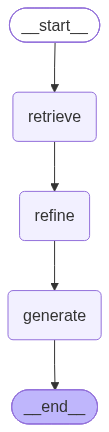

In [40]:
#---------------------------------BUILDING GRAPH-------------------------------------
graph = StateGraph(State)
graph.add_node("retrieve", retrieve)
graph.add_node("refine",refine)
graph.add_node("generate", generate)

graph.add_edge(START, "retrieve")
graph.add_edge("retrieve", "refine")
graph.add_edge("refine","generate")
graph.add_edge("generate", END)

app = graph.compile()

app

In [41]:
#-------------------------------------Run-----------------------------------------

res = app.invoke({
    "question": "Explain the bias–variance tradeoff",
    "docs": [],
    "strips": [],
    "kept_strips": [],
    "refined_context": "",
    "answer": ""
})
print(res["answer"])

* The bias-variance tradeoff is a fundamental concept in machine learning that refers to the tradeoff between the bias and variance of a model.
* A model with low bias and high variance is very flexible and fits the training data well, but may not generalize well to new data.
* A model with high bias and low variance is relatively rigid and may not fit the training data well, but is less sensitive to the particular choice of data set.
* The optimal model is the one that balances bias and variance, leading to the best predictive capability.
* The expected loss can be decomposed into three terms: (bias)², variance, and noise, where (bias)² measures the extent to which the average prediction differs from the desired regression function, and variance measures the extent to which the solutions vary around their average.
* The bias-variance decomposition is given by: expected loss = (bias)² + variance + noise.


In [42]:
print(res['docs'][0].page_content)
print('*'*100)
print(res['docs'][1].page_content)
print('*'*100)
print(res['docs'][2].page_content)
print('*'*100)
print(res['docs'][3].page_content)

to consider a frequentist viewpoint of the model complexity issue, known as thebias-
variance trade-off. Although we shall introduce this concept in the context of linear
basis function models, where it is easy to illustrate the ideas using simple examples,
the discussion has more general applicability.
In Section 1.5.5, when we discussed decision theory for regression problems,
we considered various loss functions each of which leads to a corresponding optimal
prediction once we are given the conditional distributionp(t|x). A popular choice is
****************************************************************************************************
Our goal is to minimize the expected loss, which we have decomposed into the
sum of a (squared) bias, a variance, and a constant noise term. As we shall see, there
is a trade-off between bias and variance, with very ﬂexible models having low bias
and high variance, and relatively rigid models having high bias and low variance.
The model with the 

In [43]:
print(res['refined_context'])

to consider a frequentist viewpoint of the model complexity issue, known as thebias- variance trade-off.
A popular choice is Our goal is to minimize the expected loss, which we have decomposed into the sum of a (squared) bias, a variance, and a constant noise term.
As we shall see, there is a trade-off between bias and variance, with very ﬂexible models having low bias and high variance, and relatively rigid models having high bias and low variance.
The model with the optimal predictive capability is the one that leads to the best balance between bias and variance.
The data sets are indexed by l =1 ,...,L , where L = 100, and for each data set D (l) we measures the extent to which the solutions for individual data sets vary around their average, and hence this measures the extent to which the functiony(x; D) is sensitive to the particular choice of data set.
If we substitute this expansion back into (3.37), we obtain the following decomposition of the expected squared loss expected los